# Лобораторна робота №1

Ми з вами обробляємо данні продажів у інтернет магазині. Керівництво магазину вирішило деякі товари продавати по спеціальній пропозиції (с.п.)  
Умови цієї пропозиції:
- доставка замовлень з товарами по с.п. безкоштовно
- вартість доставки всіх інших замовлень - 20грн
- якщо товар по с.п. не підійшов то його можна повернути бкзкоштовно (і лише його!)

Данні. Кожний рядок у файлі - одне замовлення для клієнта магазину:
- total: сумарна віртість замовлення  
- return: чи повернуто товар по с.п.  (True = повернуто)
- special_proposition: вартість товару зі с.п.  

Керівництво магазину зрозуміло, що деякі замовники використовують с.п. задля безкоштовного доставлення інших товарів. Нам дана задача побудувати аналітику та орієнтовно оцінити об'єми недоброчесних дій деяких замовників

In [1]:
import pandas as pd
data = pd.read_csv("data/data.csv")
data.head(4)

,Unnamed: 0,total,return,special_proposition
0,0,88.678970,False,9.141027
1,1,104.085105,True,8.569498
2,2,136.883561,False,50.300859
3,3,122.467426,False,44.532713


# Позначення
$1\leq i \leq n$  
$\xi_i + \eta_i$ - сумарна вартість замовлення (total)  
$\eta_i$ - вартість товару із с.п. (special_proposition)  
$\xi_i$ - вартість інших товарів (без с.п.) (?)  

$p_i$ - чи був товар із с.п. повернуто (return)


# 1. Об'єми повернень
В даній частині роботи нас цікавить ймовірніть того, що користувач поверне товар

### Задачі:
1. Оцініть ймовірніть повернення товару із с.п. $p$
2. Побудуйте для цієї ймовірності $p$ довірчі інтервали із рівнями 95% та 99%

(Підказка: випробування Бернулі)

In [3]:
import numpy as np
from scipy import stats

ret = data["return"].astype(bool).to_numpy()

n = len(ret)
x = ret.sum()

p_hat = x / n
se = np.sqrt(p_hat * (1 - p_hat) / n)

z95 = stats.norm.ppf(0.975)
z99 = stats.norm.ppf(0.995)

ci95 = (p_hat - z95 * se, p_hat + z95 * se)
ci99 = (p_hat - z99 * se, p_hat + z99 * se)

print("p_hat =", p_hat)
print("95% CI =", ci95)
print("99% CI =", ci99)

p_hat = 0.278
95% CI = (np.float64(0.2502323524825303), np.float64(0.30576764751746977))
99% CI = (np.float64(0.24150712526847778), np.float64(0.31449287473152227))


# 2. Вартість товарів по с.п.
В даній секції нас цікавить аналітика цін товарів по с.п.

### Задачі:
1. Оцініть середню вартість товару із с.п. $\mu$
2. Побудуйте для середньої вартості товару із с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

### Задачі:
Припустимо, що вартість товарів по с.п. ($\eta_i$) має розподіл $Exp(\lambda k)$, k>0, $\lambda$>0  
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів по с.п.
2. Оцініть параметр $\lambda k$ розподілу
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda k$

(Підказка: $\lambda k$ - один параметр, який треба оцінити)

In [8]:
eta = data["special_proposition"].to_numpy()

n_eta = len(eta)
eta_mean = eta.mean()
eta_sd = eta.std(ddof=1)

se_eta = eta_sd / np.sqrt(n_eta)

ci95_eta = (
    eta_mean - stats.norm.ppf(0.975) * se_eta,
    eta_mean + stats.norm.ppf(0.975) * se_eta
)

ci99_eta = (
    eta_mean - stats.norm.ppf(0.995) * se_eta,
    eta_mean + stats.norm.ppf(0.995) * se_eta
)

print("mean =", eta_mean)
print("95% CI =", ci95_eta)
print("99% CI =", ci99_eta)

mean = 31.323301306322005
95% CI = (np.float64(29.361800516418022), np.float64(33.28480209622599))
99% CI = (np.float64(28.74545229816553), np.float64(33.90115031447848))


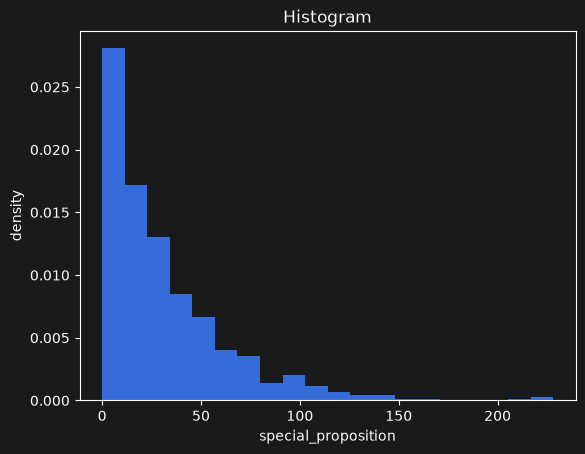

In [12]:
import matplotlib.pyplot as plt

plt.hist(eta, bins=20, density=True)
plt.xlabel("special_proposition")
plt.ylabel("density")
plt.title("Histogram")
plt.show()

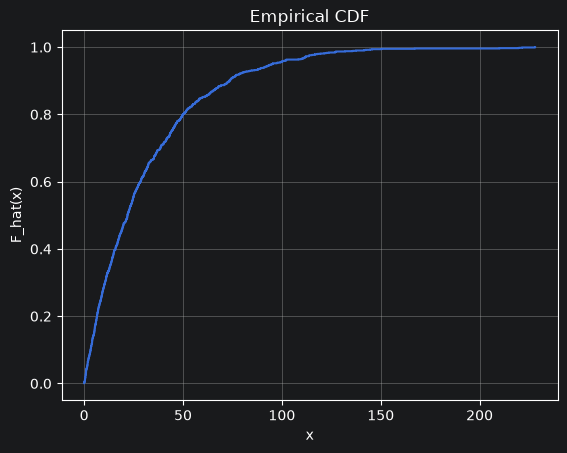

In [10]:
x_sorted = np.sort(eta)
y = np.arange(1, len(eta) + 1) / len(eta)

plt.step(x_sorted, y, where="post")
plt.xlabel("x")
plt.ylabel("F_hat(x)")
plt.title("Empirical CDF")
plt.grid()
plt.show()

In [13]:
theta_hat = 1 / eta.mean()
print("lambda*k estimate =", theta_hat)

lambda*k estimate = 0.03192511511544185


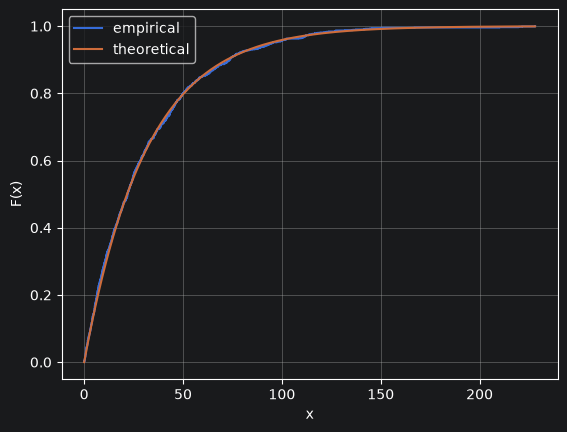

In [14]:
x_grid = np.linspace(0, eta.max(), 500)

F_theory = 1 - np.exp(-theta_hat * x_grid)

plt.step(x_sorted, y, where="post", label="empirical")
plt.plot(x_grid, F_theory, label="theoretical")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.legend()
plt.grid()
plt.show()

# 3. Інші товари
Тут нас цікавлять інші товари (без с.п.) та розподіл їх вартостей.
Тут $\xi_i$=$total - special\_proposition$

### Задачі:
1. Оцініть середню вартість товару без с.п. $\mu$
2. Побудуйте середньої вартості товару без с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

Припустимо, що вартість товарів без с.п. ($\xi_i$) має розподіл $Exp(\lambda)$, $\lambda$>0  
Увага! Тут припускаємо, що $\lambda$ тут і в пункті 2 - один і той же параметр, тобто  
($\eta_i$) має розподіл $Exp(\lambda k)$,  
($\xi_i$) має розподіл $Exp(\lambda)$,  
 k>0, $\lambda$>0  
 
### Задачі:
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів інших товарів
2. Оцініть параметр $\lambda$ розподілу. Чи буде оцінка незміщеною? Консистентною?
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda$

### Задача із:
1. (*) Запропонуйте оцінку для параметра $k$. Тут можна використати знання про розподіли цін товарів з та без с.п.
2. (*) за доведення консистентності, чи оцінка зміщена?

(*) означає - можна використати генеративний ШІ, але обов'язково розібрати його доведення так, щоб могли відповідати на мої питання

In [15]:
xi = data["total"].to_numpy() - data["special_proposition"].to_numpy()

In [16]:
lambda_hat = 1 / xi.mean()
print(lambda_hat)

0.01008404578547139


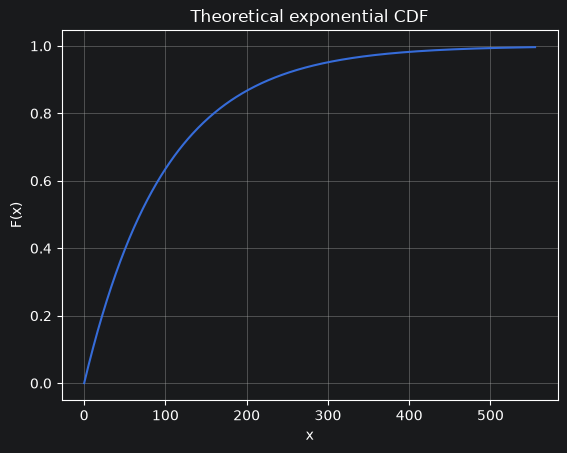

In [17]:
x_grid = np.linspace(0, xi.max(), 500)

F_xi = 1 - np.exp(-lambda_hat * x_grid)

plt.plot(x_grid, F_xi)
plt.xlabel("x")
plt.ylabel("F(x)")
plt.title("Theoretical exponential CDF")
plt.grid()
plt.show()

In [18]:
k_hat = xi.mean() / eta.mean()
print("k_hat =", k_hat)

k_hat = 3.1659034275149787


# 4. Доля с.п. у замовлені

В цьому розділі нас цікавить частка товарів з с.п. у замовленні. Тобто, величини $\frac{\eta_i}{\xi_i+\eta_i}$. Можливо, вони якось пов'язані із поверненнями.
Чи залежать поверення від частки акційних товарів? Доведіть! (побудуйте аналітику!)

У припущенні, що ($\eta_i$) має розподіл $Exp(\lambda k)$,  та ($\xi_i$) має розподіл $Exp(\lambda)$

## Задачі по варіантам:

1. Чи можливо лише по вибірці з $\frac{\eta_i}{\xi_i+\eta_i}$ оцінити параметри $\lambda$ та $k$?
2. Чи можливо лише по вибірці з $\frac{\xi_i}{\xi_i+\eta_i}$ оцінити параметри $\lambda$ та $k$?
3. Чи можливо лише по вибірці з $\frac{\xi_i}{\eta_i}$ оцінити параметри $\lambda$ та $k$?
4. Чи можливо лише по вибірці з $\xi_i + \eta_i$ оцінити параметри $\lambda$ та $k$?
5. Чи можливо лише по вибірці з $\xi_i - \eta_i$ оцінити параметри $\lambda$ та $k$?
6. Чи можливо лише по вибірці з $1/  (\xi_i + \eta_i)$ оцінити параметри $\lambda$ та $k$?

In [19]:
share = eta / data["total"].to_numpy()

returned = share[ret]
not_returned = share[~ret]

print("mean share, returned =", returned.mean())
print("mean share, not returned =", not_returned.mean())

mean share, returned = 0.04808097860461402
mean share, not returned = 0.4206548921564103


In [22]:
share = eta / data["total"].to_numpy()

returned = share[ret]
not_returned = share[~ret]

print("mean share, returned =", returned.mean())
print("mean share, not returned =", not_returned.mean())

mean share, returned = 0.04808097860461402
mean share, not returned = 0.4206548921564103


In [23]:
test = stats.ttest_ind(
    returned,
    not_returned,
    equal_var=False
)

print("t statistic =", test.statistic)
print("p-value =", test.pvalue)

t statistic = -39.48643696725064
p-value = 2.0603447143910628e-187
